# 2-DIMENSIONAL STOCHASTIC PROCESSES
 
---

We are going to make plots of 2-dimesnional stochastic processes here. They are denoted as $\{(X_t, Y_t)\}_{t \in [0,1]}$ where each $X_t$ and $Y_t$ are random variable onto $\mathbb{R}$. I plan on making them an interactive Plotly plots of $$(X_t, Y_t) = (x,y) \mapsto (X_t, Y_t, t)$$ so that once we plot a few (around 5-10) paths, we can move them around and investigate them visually. In particular, the main goal of this project is to investigate how these paths evolve over time. It falls under the purview of standard Stochastic analysis. The theory of path space is well established. We basically look at the density function the paths have at a fixed time $t$, say $p_{(X,Y)}(x,y,t)$ and then do it for all time $t$ to get the entire evolving family $$\{p(x,y,t): (x,y)  \in \mathbb{R}^2\}_t$$This will give us a family of surfaces in $\mathbb{R}^3$ for each $t$ and they are the required "density evolution" we are looking for. Static plots will not let us do that properly.

We will not dive into the theory of path space or other Stochastic & Fucntional analysis topics here ofcourse. For plots, the entire idea comes down to a discrete set up where the density surface is plotted using a simple idea of "count number of hits on a time slice". Naturally, we have to start with 1D processes to get the idea of measuring density at each time. We have python libraries for that already named `stochastic` and `aleatory`. These are 2D and static since we don't need interactive `Plotly` yet. 

## 1.1 Standard 1-dimensional Process recap

---

We make some 1D plots first. If these are things you are comfortable with you can directly to section 1.2. We will be needing these ideas extensively later on. We start witht the most famous process in Stochastic calculus directly. The Brownian motion is just random walk for us in the world of plotting since we lack the means to take limits in computer.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

We will be using the modern *random number generator: rng* always.

In [2]:
plt.style.use('seaborn-v0_8-whitegrid')  #design style
rng = np.random.default_rng(17)          

T= 1.0            #process will be on [0,T]
N = 300          #we will code N to be number of time steps
dt = T/N          #N-many steps in [o,T] will make each step dt-sized
num_paths = 6

t = np.linspace(0.0, T, N+1)                       #arranged N many linearly spaced points in [0.0, T]
dW = rng.normal(0.0, np.sqrt(dt), (num_paths, N))  #dW is increment, dW ~ N(0, sqrt(dt))

How many dW will we exactly need? Along each path we need N many and there are "num_paths" many such paths. Hence, we created (num_paths, N) shape filled with dW. Now all we need is to add them all up along a path to get the full brownian path.
$$\text{dW}  = \begin{bmatrix} w_{path0,0} & w_{path0,1} & w_{path0,2} & ... & w_{path0,N} \\ w_{path1,0} & w_{path1,1} & w_{path1,2} & ... & w_{path1, N}\\ w_{path2,0} & w_{path2,1} & w_{path2,2} & ... & w_{path2, N} \\ \vdots & \vdots & \vdots & \vdots \\ w_{num\_paths-1,0} & w_{num\_paths-1,1} & w_{num\_path-1,2} & ... & w_{num\_paths-1,N} \end{bmatrix}$$ where each $w_{path(i), j} \sim \mathcal{N}(0, \sqrt{t})$.

In [3]:
W = np.zeros((num_paths, N+1)) #created the empty array for making the path and has one extra col than dW
#W[i, :] is the i^th path and W[:, k] is the time slice at t_k = k(T/N+1) 

W[:, 1:] = np.cumsum(dW, axis=1)

`W[:, 1:]` is called the slice. Let us look at the general form directly then come back to this. 
Suppose T is a 2D array. `T[i:j, k:l]` will be from row $i$ to row $j$ and from column $k$ to column $l$. If we do not write one of the indices that would mean there is no limit in that variable.
So, `W[:, 1:]` means all rows and column starting from $1$.

`np.cumsum( ,axis=1)` is the modern operation that does the row-wise cummulutive sum and in our codes it working on $dW$:
$$\text{W[:, 1:]}  = \begin{bmatrix} w_{0,0} & w_{0,0}+w_{0,1} & w_{0,0}+w_{0,1}+w_{0,2} & ... & w_{0,0}+w_{0,1}+...+w_{0,N} \\ w_{1,0} & w_{1,0}+w_{1,1} & w_{1,0}+w_{1,1}+w_{1,2} & ... & w_{1,0}+w_{1,1}+...+w_{1, N}\\ w_{2,0} & w_{2,0}+w_{2,1} & w_{2,0}+w_{2,1}+w_{2,2} & ... & w_{2,0}+w_{2,1}+...+w_{2, N} \\ \vdots & \vdots & \vdots & \vdots \\ w_{5,0} & w_{5,0}+w_{5,1} & ... & ... & w_{5,0}+w_{5,1}+...+w_{5,N} \end{bmatrix}$$

Recall, W has the 0th column still left as 0s since we started this from the first column. This gives us the Brownian paths, one in each row and all starting at 0 (this is why we started with the the empty array of 0s with an extra column). 

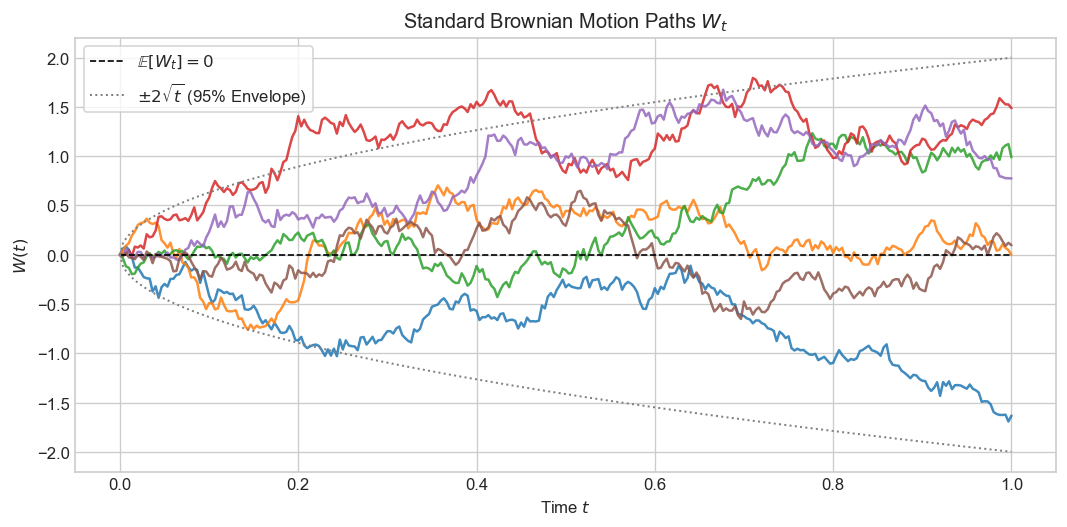

In [4]:
#irrelevant for now, code to create the actual plot.
plt.figure(figsize=(9, 4.5), dpi=120)
plt.plot(t, W.T, lw=1.5, alpha=0.85) #transpose so that time aligns with x axis

plt.plot(t, np.zeros_like(t), color='black', linestyle='--', lw=1, label=r'$\mathbb{E}[W_t] = 0$')
plt.plot(t, 2 * np.sqrt(t), color='gray', linestyle=':', lw=1.2, label=r'$\pm 2\sqrt{t}$ (95% Envelope)')
plt.plot(t, -2 * np.sqrt(t), color='gray', linestyle=':', lw=1.2)

plt.title(r'Standard Brownian Motion Paths $W_t$', fontsize=12)
plt.xlabel('Time $t$', fontsize=10)
plt.ylabel('$W(t)$', fontsize=10)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

**Note**: We choose to work with (num_paths, num_time_pts) because that is what my mathematically trained brain thinks of - each row is a path and each column is a time point, exactly what the plot looks like! But `Matplotlib`'s rule for `plt.plot(x, y)` has always been to take it the other way. Hence, just before plotting we used W.T that does the transpose. Infact, if you remove the ".T" it will show a shape-error.

We started with W that had shape $(6, N+1)$ and dW that had shape $(6, N)$. This gave us a way to keep the starting point $0$ for all the paths. There are other ways to do it that we will see as we go forward. One of them, which i like better, is to ignore the creating the $W$ step altogether. We dont need an entire 2D array of 0s, we only need the first column to be 0, we can just append it to `np.cumsum(dW, axis=1)` as `np.column_stack((np.zeros(num_paths-1, 1)), np.cumsum(dW, axis=1))`.

What is the terminal distribution of these paths? Increase the number of paths to $1000$ or $5000$ to see how most of them are at level $0.0$ and the fact that they get rarer. It is infact normally distributed.

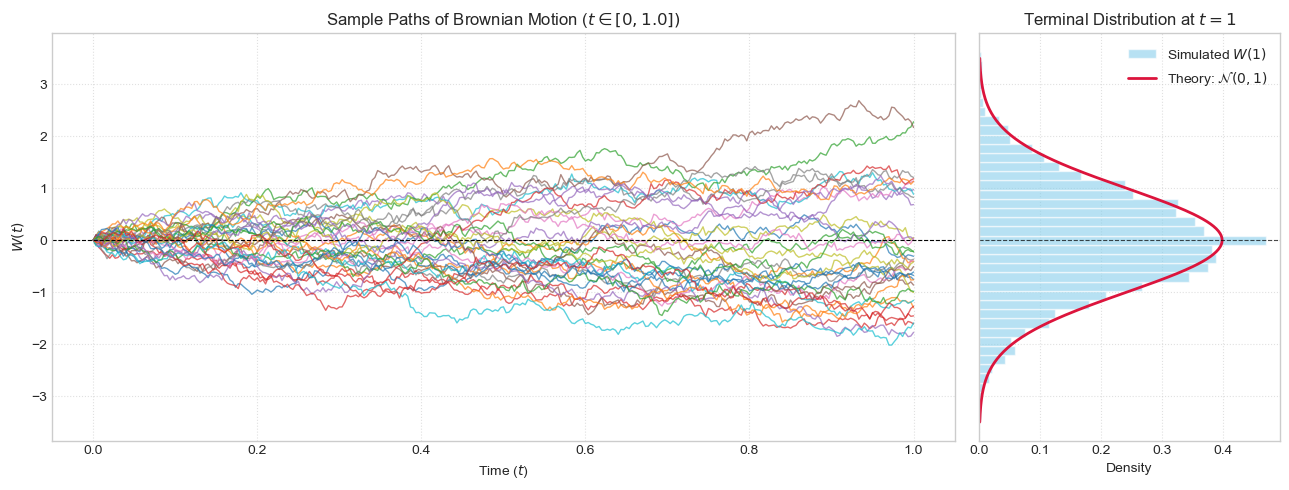

In [5]:
from scipy.stats import norm
from stochastic.processes.continuous import BrownianMotion

num_paths = 2500
#T is still 1, no need to rewrite
#Brownian motion is already there in `stochastic`. we dont need to use the above code. but we do need to know how to plot them, we are going to need them later.
bm = BrownianMotion(drift=0, scale=1, t=T)
times = bm.times(N)
#N is the no of  steps

terminal_values = np.zeros(num_paths)
paths_to_plot = 35  # Sample trajectories to display
sample_paths = []

#the path[-1] means the 1st value from the end, exactly what terminal means
for i in range(num_paths):
    path = bm.sample(N)             #creates the path with N steps
    terminal_values[i] = path[-1]   #use the path we created above
    if i < paths_to_plot:
        sample_paths.append(path)

#plot paths and terminal distribution side-by-side, hence the ax1 and ax2 (just two names for two side by sid eplot, you could do axes1 and axes2 too)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), sharey=True, gridspec_kw={"width_ratios": [3, 1]})
#subplots(1, 2,..) means 1 row 2 cols, so we get two side by side plots, sharey=True makes them share the same y axis, you will see the distribution's plot wont have y ticks

#plot sample paths
for path in sample_paths:
    ax1.plot(times, path, alpha=0.7, linewidth=1)

ax1.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=1)
ax1.set_title(f"Sample Paths of Brownian Motion ($t \\in [0, {T}])$")
ax1.set_xlabel("Time ($t$)")
ax1.set_ylabel("$W(t)$")
ax1.grid(True, linestyle=":", alpha=0.6)

# Plot terminal distribution histogram (horizontal to align with paths). 
#try various vlues of bins to see what it does. we will come back to density later.
counts, bins, _ = ax2.hist(
    terminal_values,
    bins=40,
    density=True,
    orientation="horizontal",
    alpha=0.6,
    color="skyblue",
    edgecolor="white",
    label="Simulated $W(1)$",
)

# Overlay theoretical distribution: N(0, 1)
#norm.pdf(y,0,root(T)) evaluates the pdf at values of y, ie, for y_0 in y: f(y_0) = exp(-(y_0^2-mean)/2T/root(2 pi t) 
y = np.linspace(-3.5, 3.5, 300)
theoretical_pdf = norm.pdf(y, loc=0, scale=np.sqrt(T))
ax2.plot(theoretical_pdf, y, color="crimson", linewidth=2, label="Theory: $\\mathcal{N}(0, 1)$",)

ax2.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.7)
ax2.set_title("Terminal Distribution at $t = 1$")
ax2.set_xlabel("Density")
ax2.legend()
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

Did you try different values for bins? It literally creates bins where the paths end up at and count them to create the histogram. Generally, a histogram counts how many sampled points fall into each bin (e.g., 50 paths ended here, 120 paths ended there). `density=True` normalizes these counts so that the total area under the histogram bars equals 1, converting raw sample counts into an empirical probability density function (PDF). Once you remove the `density=True` part, it will just show counts. The crimson curve showing the actual theoretical pdf is due to the code block under "# Overlay theoretical distribution: N(0, 1)".  

 Understanding these roles are important, since we will try to replicate these in 3D.

We will get a normal distribution no matter what time slice we look at. The variance increases and to maintain the pdf property of having area 1 under it, the peak will decrease. 

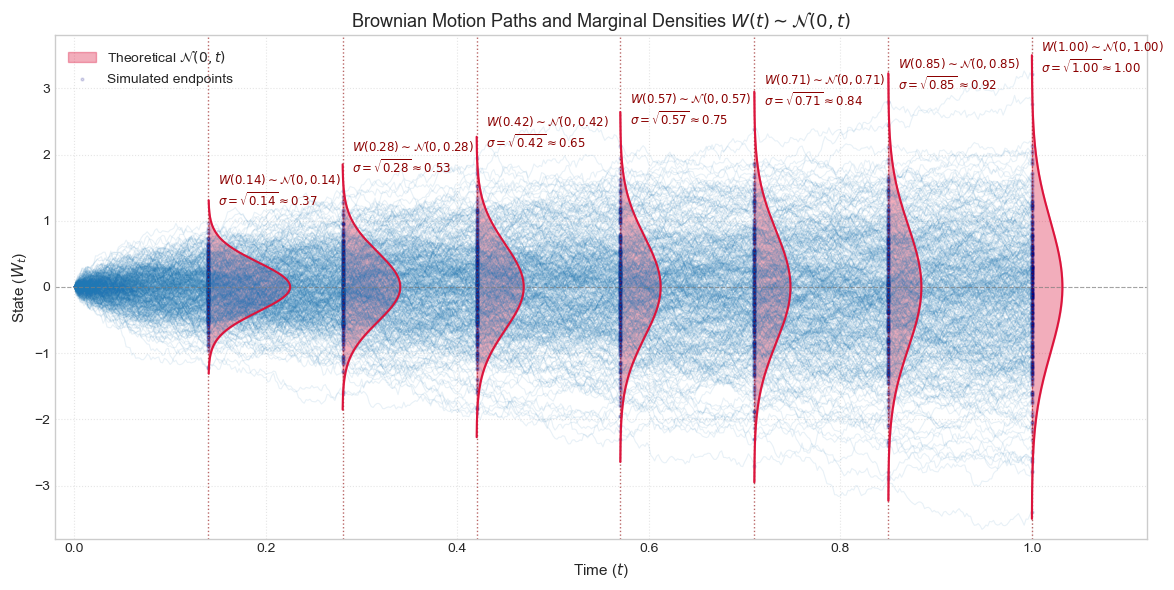

In [6]:
#Simulation set up
T = 1.0 #t_end
N = 500 #n_step
num_paths = 400 #n_paths
time_slices = [0.14, 0.28, 0.42, 0.57, 0.71, 0.85, 1.00]

#Simulate paths using stochastic, as stated before, stochastic has predefined brownian motion
bm = BrownianMotion(drift=0, scale=1, t=T)
times = bm.times(N)

# Generate path matrix: shape (num_paths, N + 1)
paths = np.array([bm.sample(N) for _ in range(num_paths)])

#Create plot
fig, ax = plt.subplots(figsize=(12, 6))

# Plot all paths with low alpha to reveal the trajectory density
for i in range(num_paths):
    ax.plot(times, paths[i], color="#1f77b4", alpha=0.1, linewidth=0.8)

# Baseline zero line
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)

# 4. Overlay marginal density curves at each chosen time point
# Scale factor converts PDF height into x-axis time units for visualization
pdf_scale = 0.08  #just out choice, once the entire plot is done change this as u see fit

for t_val in time_slices:
    # Find the nearest time point where we have a "step" for bm from "t_val"
    idx = np.argmin(np.abs(times - t_val))
    actual_t = times[idx]
    slice_data = paths[:, idx]
    # so for example we have t_val=0.25 but if we do not have that as one of the T/N points, we look at the nearest point, may be 0.27

    # Grid for theoretical PDF evaluation
    std_t = np.sqrt(actual_t)                             #var
    w_grid = np.linspace(-3.5 * std_t, 3.5 * std_t, 250)  #the bins at t_vals
    pdf_vals = norm.pdf(w_grid, loc=0, scale=std_t)       #recall this does the actual calculation of pdf at w belonging to w_grid

    # Shift pdf curve horizontally and anchor it at t = actual_t
    #this is the most important part of the code
    x_pdf = actual_t + pdf_vals * pdf_scale
    #This is just the numpy 1D array due to pdf_vals, we will actually plot it using ax.fill_betweenx

    # Reference timeline line
    ax.axvline(actual_t, color="darkred", linestyle=":", linewidth=1, alpha=0.6)

    #Fill and outline theoretical normal density curve: N(0, t)
    #this is the 2nd most important part of the code: 
    #ax.fill_betweenx(w_grid, actual_t, x_pdf): Fills the shaded region between the baseline x = actual_t & the outer edge x = x_pdf across all vertical points w_grids
    ax.fill_betweenx(w_grid, actual_t, x_pdf, 
                     color="crimson", 
                     alpha=0.35, 
                     label=("Theoretical $\\mathcal{N}(0, t)$" if t_val == time_slices[0]
                                                               else None),
    )
    ax.plot(x_pdf, w_grid, color="crimson", linewidth=1.5)

    # Optional: Plot empirical slice points as small ticks along the axis line
    ax.scatter(
        np.full_like(slice_data, actual_t),
        slice_data,
        color="navy",
        s=4,
        alpha=0.15,
        label="Simulated endpoints" if t_val == time_slices[0] else None,
    )

    # Label with the distribution parameters
    ax.text(
        actual_t + 0.01,
        3.2 * std_t,
        f"$W({actual_t:.2f}) \\sim \\mathcal{{N}}(0, {actual_t:.2f})$\n$\\sigma = \\sqrt{{{actual_t:.2f}}} \\approx {std_t:.2f}$",
        fontsize=8.5,
        color="darkred",
        verticalalignment="bottom",
    )

ax.set_title(
    "Brownian Motion Paths and Marginal Densities $W(t) \\sim \\mathcal{N}(0, t)$",
    fontsize=13,
)
ax.set_xlabel("Time ($t$)", fontsize=11)
ax.set_ylabel("State ($W_t$)", fontsize=11)
ax.set_xlim(-0.02, T + 0.12)
ax.set_ylim(-3.8, 3.8)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

Note that, $X_t \sim iid (\mathcal{N}(0, t))$ will ofcourse not create Brownian motion. I mean obviously, why will it? There are other statistical properties of Brownian motion other than $W_t \sim iid (\mathcal{N}(0, t))$. But let us see it visually too.


Let us next see how to plot processes $\{X_t\}_t$ where $X_t \sim iid (\mathcal{D})$ for some distribution $\mathcal{D}$. We will look at the standard $\mathcal{N}(\mu, \sigma)$, Cauchy$(0,1)$, etc as $\mathcal{D}$. 

As opposed to Brownian process we plotted, with the envelope that encaptures how it spreads, in general the iid processes do not have such interesting envelopes. Statistically they are distributed with the constant envelope $\mu \pm k\sigma$. Let's us make $\{X_t\}_t$ where $X_t \sim \mathcal{N}(\mu, \sigma)$ and by it's side a plot of a process that is not stationary. Let us do something different now, we know already before plotting we will have to take transpose, sine we know that already let us try and use the inverted shape to begin with:
The variable increments (that we are going to define next) was created with size=(N, num_paths), meaning it is a 2D matrix of shape (1000, 5):$$\text{increments} = \begin{bmatrix}
x_{0, \text{path0}} & x_{0, \text{path1}} & \dots & x_{0, \text{path4}} \\
x_{1, \text{path0}} & x_{1, \text{path1}} & \dots & x_{1, \text{path4}} \\
\vdots & \vdots & \ddots & \vdots \\
x_{999, \text{path0}} & x_{999, \text{path1}} & \dots & x_{999, \text{path4}}
\end{bmatrix}$$

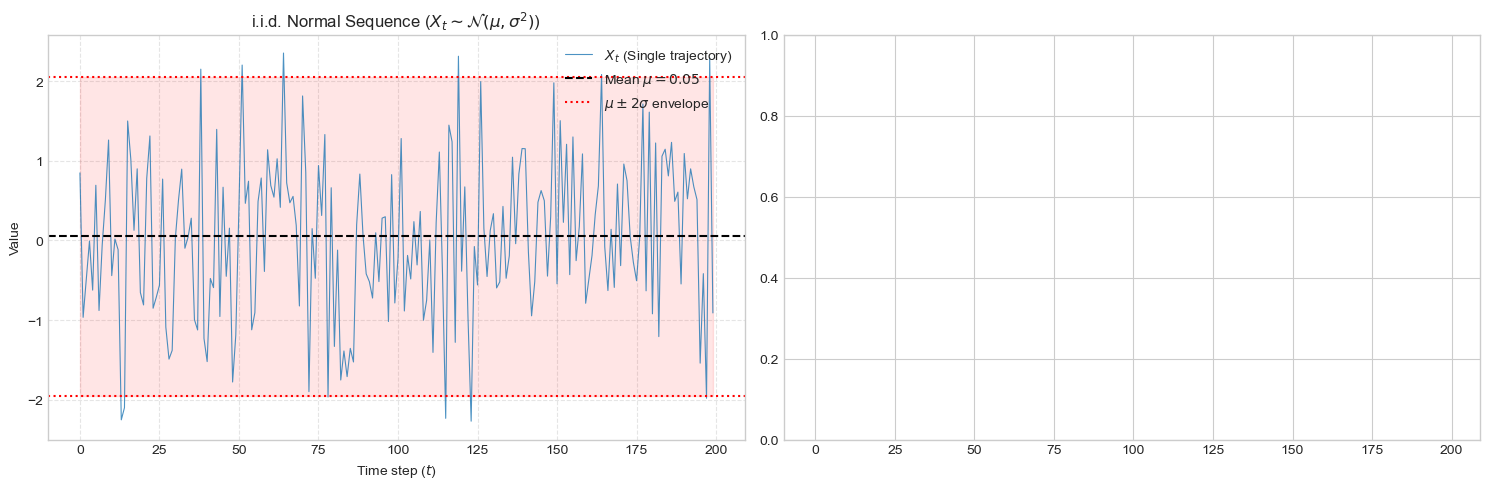

In [7]:
N = 1000
num_paths = 5
mu = 0.05
sigma = 1.0

t = np.arange(N)
#Shape: (N, num_paths)
increments = rng.normal(loc=mu, scale=sigma, size=(N, num_paths))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), sharex=True)

# we will write 3 ways to plot it next, u can uncomment and try any one of the three once u comment out the other two

#writing the next line of code will create all 5 paths, on N steps; 
#ax1.plot(t, increments, color="tab:blue", lw=0.8, alpha=0.8,)

#This will create only one path, with N steps still; from the 2d matrix we wrote above we pick the 0th col only, hence one path
# ax1.plot(t, increments[:, 0], color="tab:blue", lw=0.8, alpha=0.8, label="$X_t$ (Single trajectory)")

#my choice is this, only one path over smaller amount of time (only first 200 steps, 0 to 199) and as for increments we take time 0-199 and col 0 (one path only) 
ax1.plot(t[:200], increments[:200, 0], color="tab:blue", lw=0.8, alpha=0.8, label="$X_t$ (Single trajectory)")

#legends
ax1.axhline(mu, color="black", linestyle="--", label=f"Mean $\mu={mu}$")
ax1.axhline(mu + 2 * sigma, color="red", linestyle=":", label="$\mu \pm 2\sigma$ envelope")
ax1.axhline(mu - 2 * sigma, color="red", linestyle=":")

ax1.fill_between(t[:200], mu - 2 * sigma, mu + 2 * sigma, color="red", alpha=0.1)
ax1.set_title("i.i.d. Normal Sequence ($X_t \sim \mathcal{N}(\mu, \sigma^2)$)")
ax1.set_xlabel("Time step ($t$)")
ax1.set_ylabel("Value")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right")

plt.tight_layout()
plt.show()

Now we will create the 2nd plot. We need to rewrite the `fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), sharex=True)` part again because in the last piece of code not only did we start it but also executed it by `plt.tight_layout()
plt.show()`, hence closed it. So, we have to open it again and then, write the first plot again, THEN add the second plot. Now we need the time axis to be $[0, 1000]$ for the 2nd plot, or else it will not look like a brownian motion. But since the first process is still stuck at $199$, we will get an empty space on $[200, 1000]$. That can be automatically managed once we remove `sharex=True` from `.subplots()` initialization.

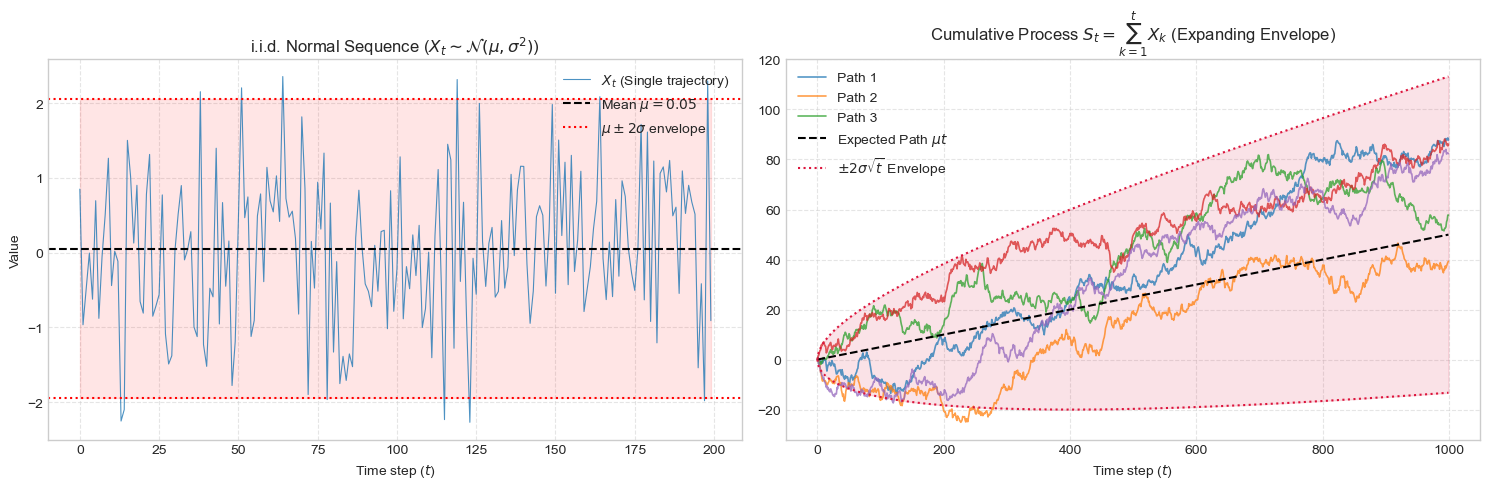

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.plot(t[:200], increments[:200, 0], color="tab:blue", lw=0.8, alpha=0.8, label="$X_t$ (Single trajectory)")

#legends
ax1.axhline(mu, color="black", linestyle="--", label=f"Mean $\mu={mu}$")
ax1.axhline(mu + 2 * sigma, color="red", linestyle=":", label="$\mu \pm 2\sigma$ envelope")
ax1.axhline(mu - 2 * sigma, color="red", linestyle=":")

ax1.fill_between(t[:200], mu - 2 * sigma, mu + 2 * sigma, color="red", alpha=0.1)
ax1.set_title("i.i.d. Normal Sequence ($X_t \sim \mathcal{N}(\mu, \sigma^2)$)")
ax1.set_xlabel("Time step ($t$)")
ax1.set_ylabel("Value")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right")

#NEW PART FOR THE 2ND PLOT

paths = np.vstack([np.zeros((1, num_paths)), np.cumsum(increments[:-1], axis=0)]) #we explain this after the plot, for now just assume this creates the paths

#Theoretical mean and standard deviation envelopes
theoretical_mean = mu * t
envelope_upper = theoretical_mean + 2 * sigma * np.sqrt(t)
envelope_lower = theoretical_mean - 2 * sigma * np.sqrt(t)

for i in range(num_paths):
    ax2.plot(t, paths[:, i], lw=1.2, alpha=0.75, label=f"Path {i+1}" if i < 3 else None)

ax2.plot(t, theoretical_mean, color="black", linestyle="--", lw=1.5, label="Expected Path $\mu t$")
ax2.plot(t, envelope_upper, color="crimson", linestyle=":", lw=1.5, label=r"$\pm 2\sigma\sqrt{t}$ Envelope")
ax2.plot(t, envelope_lower, color="crimson", linestyle=":", lw=1.5)
ax2.fill_between(t, envelope_lower, envelope_upper, color="crimson", alpha=0.12)
ax2.set_title(r"Cumulative Process $S_t = \sum_{k=1}^t X_k$ (Expanding Envelope)")
ax2.set_xlabel("Time step ($t$)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()

Explainer for `np.vstack([np.zeros((1, num_paths)), np.cumsum(increments[:-1], axis=0)])` part of the code:
1. `np.zeros((1, n_trajectories))` creates a $1 \times 4$ row of zeros: $[[0.0, 0.0, 0.0, 0.0]]$
2.  The increments array has shape (1000, 4). Slicing `[:-1]` takes everything except the last row, yielding rows $0$ through $998$.The resulting shape is $(999, 4)$: $$\text{increments}[:-1] = \begin{bmatrix}
x_{0, \text{path0}} & x_{0, \text{path1}} & \dots & x_{0, \text{path4}} \\
x_{1, \text{path0}} & x_{1, \text{path1}} & \dots & x_{1, \text{path4}} \\
\vdots & \vdots & \ddots & \vdots \\
x_{998, \text{path0}} & x_{998, \text{path1}} & \dots & x_{998, \text{path4}}
\end{bmatrix}$$
3. `np.cumsum(increments[:-1], axis=0)` does the column wise sums of above sliced matrix.
4. `np.vstack([a,b])` stack $a$ above $b$ vertically.
So, we finally get the required matrix:
$$\text{paths} = \begin{bmatrix} \text{np.zeros} \\ \hline \text{np.cumsum} \end{bmatrix} = \begin{bmatrix} 0 & 0 & 0 & 0 \\ X_0 & X_0 & X_0 & X_0 \\ X_0 + X_1 & X_0 + X_1 & X_0 + X_1 & X_0 + X_1 \\ \vdots & \vdots & \vdots & \vdots \\ \sum_{k=0}^{998} X_k & \dots & \dots & \dots \end{bmatrix}$$

You do see why investigating the terminal distribution for $iid$ processes is redundant right? At any time $t$, it is distributed $\mathcal{D}$ anyway, we dont need to examine terminal distribution.

Now we move to Cauchy. The standard Cauchy distribution has the probability density function:$$f(x) = \frac{1}{\pi (1 + x^2)}$$It represents the classic breakdown of textbook statistics because its tails decay as $O(x^{-2})$.

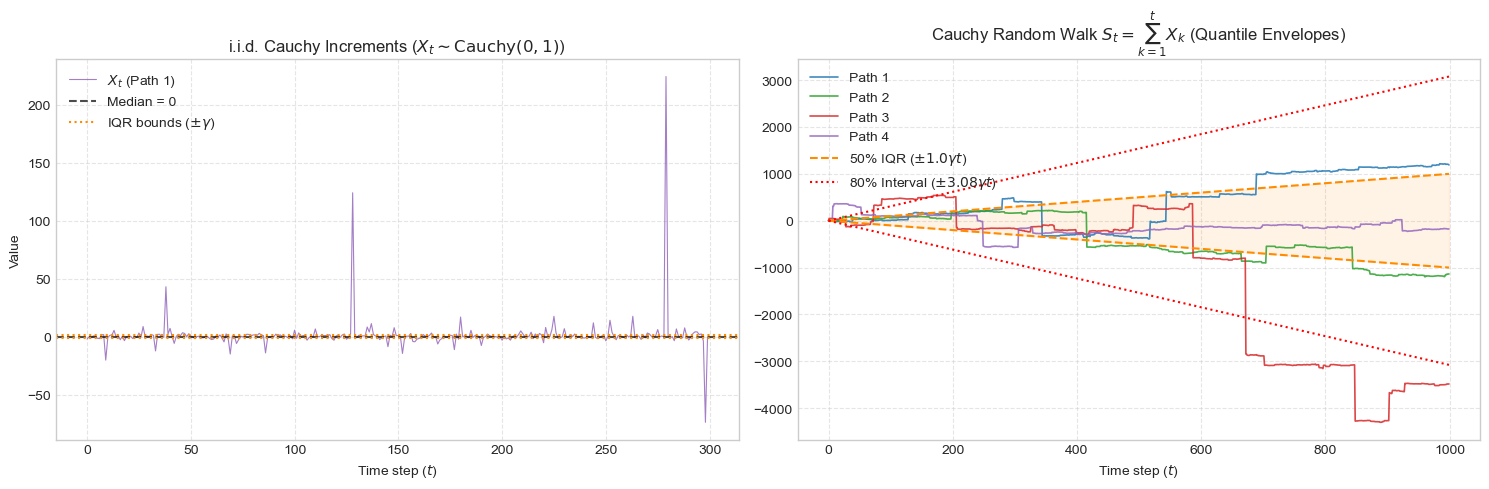

In [9]:
N = 1_000
num_paths = 4
gamma = 1.0  # Scale parameter

# Time grid
t = np.arange(N)

#Generate i.i.d. Cauchy increments
#Shape: (N, num_paths) so as to avoid taking the transpose 
increments = rng.standard_cauchy(size=(N, num_paths)) * gamma

#make the plotting window
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

#finish the ax1 plot
ax1.plot(t[:300], increments[:300, 0], color="tab:purple", lw=0.8, alpha=0.85, label="$X_t$ (Path 1)")
ax1.axhline(0, color="black", linestyle="--", alpha=0.7, label="Median = 0")
ax1.axhline(gamma, color="darkorange", linestyle=":", label=r"IQR bounds ($\pm \gamma$)")
ax1.axhline(-gamma, color="darkorange", linestyle=":")
ax1.set_title("i.i.d. Cauchy Increments ($X_t \sim \mathrm{Cauchy}(0, 1)$)")
ax1.set_xlabel("Time step ($t$)")
ax1.set_ylabel("Value")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper left")


#2nd PART FOR THE PLOT
#Cumulative sum (Cauchy random walk / discrete Cauchy flight)
paths = np.vstack([np.zeros((1, num_paths)), np.cumsum(increments[:-1], axis=0)])

#Theoretical Quantile Envelopes (replacing the non-existent variance envelope)
# 50% central interval (Interquartile Range): p = 0.25 to 0.75 -> factor = tan(pi * 0.25) = 1.0
iqr_upper = gamma * t * np.tan(np.pi * 0.25)   # + 1.0 * gamma * t
iqr_lower = -iqr_upper

# 80% central interval: p = 0.10 to 0.90 -> factor = tan(pi * 0.40) ~= 3.078
q80_upper = gamma * t * np.tan(np.pi * 0.40)
q80_lower = -q80_upper

# 2B: Cumulative Process with Quantile Envelopes
colors = ["#1f77b4", "#2ca02c", "#d62728", "#9467bd"]
for i in range(num_paths):
    ax2.plot(t, paths[:, i], lw=1.2, alpha=0.85, color=colors[i], label=f"Path {i+1}")

# Plot quantile bands
ax2.plot(t, iqr_upper, color="darkorange", linestyle="--", lw=1.5, label=r"50% IQR ($\pm 1.0 \gamma t$)")
ax2.plot(t, iqr_lower, color="darkorange", linestyle="--", lw=1.5)
ax2.plot(t, q80_upper, color="red", linestyle=":", lw=1.5, label=r"80% Interval ($\pm 3.08 \gamma t$)")
ax2.plot(t, q80_lower, color="red", linestyle=":", lw=1.5)
ax2.fill_between(t, iqr_lower, iqr_upper, color="darkorange", alpha=0.1)

ax2.set_title(r"Cauchy Random Walk $S_t = \sum_{k=1}^t X_k$ (Quantile Envelopes)")
ax2.set_xlabel("Time step ($t$)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()

Note how far they have ventured within $1000$ steps, the usual WN random walk would have gone $\sqrt{t}$, that is, $[-100, 100]$ only. We now see Poisson processes related plots.


A homogeneous Poisson process $N_t$ with intensity $\lambda > 0$ counts the number of discrete arrivals up to time $t$.
Theoretical Properties
1. Increments: For any disjoint time interval $\Delta t$, the increment is Poisson distributed:$$\Delta N_t = N_{t+\Delta t} - N_t \sim \text{Poisson}(\lambda \Delta t)$$
2. Moments of $N_t$: Mean is $\mathbb{E}[N_t] = \lambda t$; variance is $\operatorname{Var}(N_t) = \lambda t$ and envelope ($\pm 2\sigma$): $\lambda t \pm 2\sqrt{\lambda t}$

Subtracting the deterministic expected rate yields the compensated Poisson process:$$\tilde{N}_t = N_t - \lambda t$$Mean: $\mathbb{E}[\tilde{N}_t] = 0$; variance: $\operatorname{Var}(\tilde{N}_t) = \lambda t$; 

Martingale property: $\mathbb{E}[\tilde{N}_t \mid \mathcal{F}_s] = \tilde{N}_s$ for all $s \le t$ and envelope is ($\pm 2\sigma$): $0 \pm 2\sqrt{\lambda t}$

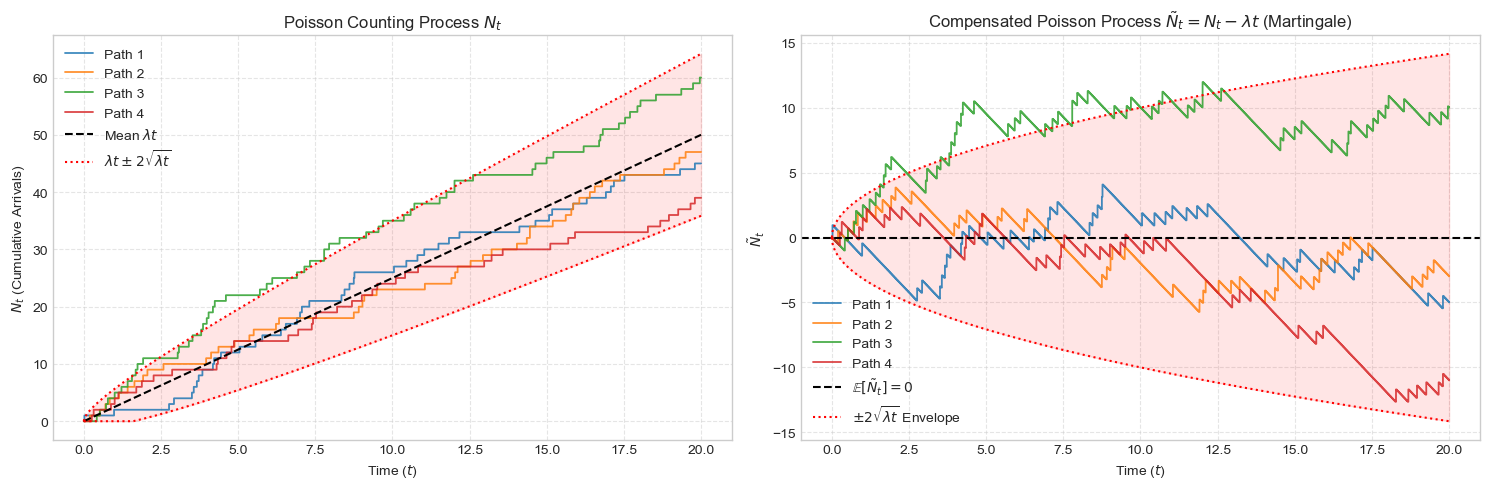

In [15]:
T = 20.0
n_steps = 1000 #we are not using N for no of steps since N denote the Poisson process 
num_paths = 4
lam = 2.5  # Arrival rate lambda (events per unit time)

# Time grid
t = np.linspace(0.0, T, n_steps)
dt = t[1] - t[0]

#Generate increments: Delta N_t ~ Poisson(lambda * dt)
# Shape: (n_steps - 1, num_paths), so again we do not need the transpose. We are taking one row less so that we can vstack 0s next and all paths will start from 0
increments = rng.poisson(lam=lam * dt, size=(n_steps - 1, num_paths))

#Cumulative counting process N_t starting at N_0 = 0
n_paths = np.vstack([np.zeros((1, num_paths)), np.cumsum(increments, axis=0)])

#Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

#Theoretical Envelopes for N_t
mean_n = lam * t
sd_n = np.sqrt(lam * t)
env_n_upper = mean_n + 2 * sd_n
env_n_lower = np.maximum(0.0, mean_n - 2 * sd_n)  # N_t cannot be negative

# For N~_t
env_comp_upper = 2 * sd_n
env_comp_lower = -2 * sd_n

#finish ax1 first, raw counting process N_t
for i in range(num_paths):
    ax1.plot(t, n_paths[:, i], drawstyle="steps-post", 
             lw=1.3, alpha=0.85, 
             label=f"Path {i+1}", )

ax1.plot(t, mean_n, color="black", linestyle="--", lw=1.5, label=r"Mean $\lambda t$")
ax1.plot(t, env_n_upper, color="red", linestyle=":", lw=1.5, label=r"$\lambda t \pm 2\sqrt{\lambda t}$")
ax1.plot(t, env_n_lower, color="red", linestyle=":", lw=1.5)
ax1.fill_between(t, env_n_lower, env_n_upper, color="red", alpha=0.1)

ax1.set_title(r"Poisson Counting Process $N_t$")
ax1.set_xlabel("Time ($t$)")
ax1.set_ylabel(r"$N_t$ (Cumulative Arrivals)")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper left")

#THE 2ND PLOT of Compensated Poisson process: N~_t = N_t - lambda * t
drift = lam * t[:, np.newaxis]
compensated_paths = n_paths - drift

for i in range(num_paths):
    ax2.plot(t, compensated_paths[:, i],
             drawstyle="steps-post",
             lw=1.3, alpha=0.85,
             label=f"Path {i+1}",)

ax2.axhline(0.0, color="black", linestyle="--", lw=1.5, label=r"$\mathbb{E}[\tilde{N}_t] = 0$")
ax2.plot(t, env_comp_upper, color="red", linestyle=":", lw=1.5, label=r"$\pm 2\sqrt{\lambda t}$ Envelope")
ax2.plot(t, env_comp_lower, color="red", linestyle=":", lw=1.5)
ax2.fill_between(t, env_comp_lower, env_comp_upper, color="red", alpha=0.1)

ax2.set_title(r"Compensated Poisson Process $\tilde{N}_t = N_t - \lambda t$ (Martingale)")
ax2.set_xlabel("Time ($t$)")
ax2.set_ylabel(r"$\tilde{N}_t$")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()